# Table of contents

- [Introduction](#Introduction)
- [Import libraries and package](#Import-libraries-and-packages)
- [Optimization for Calculation](#Optimization-for-Calculation)
- [Import Dataset](#Import-Dataset)
- [Checking Null/NA values ](#Checking-Null-and-NA-value)
- [Preprocessing Date and convert into Datatime format](#Convert-Date-field-into-datetime-format)
- [Perform Exploratory Data Analysis(EDA)](#EDA---Exploratory-Data-Analysis)
    - [Find the duration of dataset](#Find-the-duration-of-dataset)
    - [Monthwise comparision between Stock open and close price](#Monthwise-comparision-between-Stock-open-and-close-price)
    - [Monthwise High and Low stock price](#Monthwise-High-and-Low-stock-price)
    - [Trend comparision between stock open price, close price, high price, low price](#Trend-comparision-between-stock-open-price,-close-price,-high-price,-low-price)
    - [Volume trend](#volume-trend)
    - [Pairplot between price and volume data](#pairplot-betweeen-price-data-and-volume-data)
- [Preprare Stock Close price](#prepare-stock-close-price)
    - [Make separate dataframe](#make-separate-dataframe-of-close-price)
    - [Plot stock close price](#plotting-stock-close-price-chart)
- [Consider only 5 year data for prediction](#consider-period-for-prediction)
    - [Feature Engineering](#feature-engineering)
        - [Visualization of Moving Averages](#visualization-of-moving-averages)
        - [Visualization of Movign Average Convergence & Divergence (MACD)](#visualizaiton-of-moving-average-convergence--divergence-(MACD))
        - [Viusalization of Relative Strength Index (RSI)](#visualization-of-relative-index-strength-(RSI))
        - [Visualization of Pivot Points and Average True Range](#visualization-of-pivot-points-and-average-true-range)
        - [Viusalization of Bollinger Bands](#visualization-of-bollinger-band)
        - [Viusalization of On Balance Volume & Stochastic Oscillator](#visualization-of-on-balance-volume-and-stochastic-oscillator)
        - [Correlation of Featured Data](#correlation-of-feature-data)
        - [Trend Comparison between close & Average True Range](#trend-comparison-between-close-price-and-atr)
        - [Relationships between Featured Data](#relationship-of-featured-data)
    - [Normalizing close price](#normalizing-close-price)
    - [Split Train and Test ](#prepare-data-for-train-and-test)
    - [Plot of training, validation, and test data](#plot-of-training-validation-and-test-data)
    - [Transform Close price base on Time-series-analysis forecasting requirement](#transform-close-price-base-on-time-series-analysis-forecasting-requirement)
- [Model Building (LSTM) ](#model-building-LSTM)
    - [Model Training (Save and Load model)](#model-training)
    - [Prediction on train, validation, and test data](#prediciton-on-train-validation-and-test-data)
- [Plotting Loss chart](#plotting-loss-chart)
- [Model Evaluation](#model-evaluation)
    - [Inverse transform predictions & Comparison between predicted values and original values](#inverse-transform-prediction--comparison-between-predicted-values-with-original-values)
    - [Evaluation metrices RMSE, MSE and MAE](#evaluation-metrices-rmse-mse-and-mae)
    - [Explained variance regression score](#explained-variance-regression-score)
    - [R<sup>2</sup> score for regression](#r2-score-for-regression)
    - [Regression Loss Mean Gamma deviance regression loss (MGD) and Mean Poisson deviance regression loss (MPD)](#regression-loss-mean-gamma-deviance-regression-loss-mgd-and-mean-poisson-deviance-regression-loss-mpd)
- [Prediction Comparison](#predictions-comparison)
    - [Performance Comparision of original stock close price and predicted close price](#performance-comparision-of-original-stock-close-price-and-predicted-close-price)
    - [Performance Comparison of close data model and feature data model in test period](#performance-comparison-between-close-data-model-and-feature-data-model-in-test-period)
    - [Visualization of Outliers Predictions](#visualization-of-outlier-predictions)
- [Conclusion and Insights](#conclusion-and-insights)

# Introduction


> **Time series is a sequence or series of data points in which the time component is involved throughout the occurrence and Analyzing this time series data with certain tools and techniques is called time series analysis.**

Here, we have a last 5 years Stock Data of the most fastest growing company which is TESLA.
We plan to use two dataset to show the performance of the prediction so that the more information the model receive, will it have a better predictions?
- **Training using only close price data (closedf)**
- **Training using Open, High, Low, Close price data and calculated feature data through feature engineering (pricedf)**

In this notebook, You will be going to learn following: 
- **EDA Techniques**
- **Plotting basic charts using Plotly**
- **Easily learn about Time series analysis using LSTM neural network** 
- **Prediction recent year data** 

# Import libraries and packages

In [ ]:
import os
# Set environment variables before importing tensorflow
os.environ["TF_DETERMINISTIC_OPS"] = "1"
# Optional: Limit TensorFlow to a single CPU thread for reproducibility
os.environ['TF_CPP_MIN_LOG_LEVEL'] = '2'  # Suppress some TensorFlow logs
os.environ['PYTHONHASHSEED'] = str(42)
import warnings
warnings.filterwarnings("ignore")
import random
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import math
import datetime as dt

from sklearn.metrics import mean_squared_error, mean_absolute_error, explained_variance_score, r2_score 
from sklearn.metrics import mean_poisson_deviance, mean_gamma_deviance
from sklearn.preprocessing import MinMaxScaler

import tensorflow as tf
from keras.api.models import Sequential
from keras.api.layers import Dense, Dropout
from keras.api.layers import LSTM
from tensorflow._api.v2.config import threading

from itertools import cycle
import plotly.graph_objects as go
import plotly.express as px
from plotly.subplots import make_subplots
import yfinance as yf

# Train model use True else use False
TRAINING = False

In [142]:
# Get current working directory
current_path = os.getcwd()

print(f"Current Path: {current_path}")

Current Path: /Users/keven/Downloads/all/lstm


# Optimization for Calculation

In [143]:
def set_seeds(seed=42):
    # Set seed for TensorFlow
    tf.random.set_seed(seed)
    # Set seed for numpy
    np.random.seed(seed)
    # Set seed for Python's random module
    random.seed(seed)
    # Set environmental variable to improve reproducibility
    os.environ['PYTHONHASHSEED'] = str(seed)

# Call this function before any TensorFlow code to ensure reproducibility
set_seeds(42)

# Limit TensorFlow to a single CPU thread (optional, for reproducibility)
tf.config.threading.set_intra_op_parallelism_threads(1)
tf.config.threading.set_inter_op_parallelism_threads(1)

In [144]:
print("Num GPUs Available: ", len(tf.config.list_physical_devices('GPU')))

Num GPUs Available:  0


# Import Dataset

In [145]:
maindf = yf.download('TSLA', start='2015-01-01')
maindf.head()

[*********************100%***********************]  1 of 1 completed


Price,Adj Close,Close,High,Low,Open,Volume
Ticker,TSLA,TSLA,TSLA,TSLA,TSLA,TSLA
Date,,,,,,
2015-01-02 00:00:00+00:00,14.620667,14.620667,14.883333,14.217333,14.858000,71466000
2015-01-05 00:00:00+00:00,14.006000,14.006000,14.433333,13.810667,14.303333,80527500
2015-01-06 00:00:00+00:00,14.085333,14.085333,14.280000,13.614000,14.004000,93928500
2015-01-07 00:00:00+00:00,14.063333,14.063333,14.318667,13.985333,14.223333,44526000
2015-01-08 00:00:00+00:00,14.041333,14.041333,14.253333,14.000667,14.187333,51637500


In [146]:
"""RESET INDEX AFTERWARD"""
maindf.to_csv('TSLA_dataset.csv')
maindf = pd.read_csv('TSLA_dataset.csv')
maindf = maindf.iloc[2:]
maindf = maindf.reset_index(drop=True)

maindf.head()

,Price,Adj Close,Close,High,Low,Open,Volume
0,2015-01-02 00:00:00+00:00,14.620667457580566,14.620667457580566,14.883333206176758,14.21733283996582,14.857999801635742,71466000
1,2015-01-05 00:00:00+00:00,14.005999565124512,14.005999565124512,14.433333396911621,13.810667037963867,14.303333282470703,80527500
2,2015-01-06 00:00:00+00:00,14.085332870483398,14.085332870483398,14.279999732971191,13.61400032043457,14.003999710083008,93928500
3,2015-01-07 00:00:00+00:00,14.063332557678223,14.063332557678223,14.3186674118042,13.985333442687988,14.223333358764648,44526000
4,2015-01-08 00:00:00+00:00,14.041333198547363,14.041333198547363,14.25333309173584,14.000666618347168,14.187333106994629,51637500


In [147]:
del maindf['Adj Close']
maindf = maindf.rename(columns={'Price': 'date','Open':'open','High':'high','Low':'low','Close':'close','Volume':'volume'})

maindf.head()

,date,close,high,low,open,volume
0,2015-01-02 00:00:00+00:00,14.620667457580566,14.883333206176758,14.21733283996582,14.857999801635742,71466000
1,2015-01-05 00:00:00+00:00,14.005999565124512,14.433333396911621,13.810667037963867,14.303333282470703,80527500
2,2015-01-06 00:00:00+00:00,14.085332870483398,14.279999732971191,13.61400032043457,14.003999710083008,93928500
3,2015-01-07 00:00:00+00:00,14.063332557678223,14.3186674118042,13.985333442687988,14.223333358764648,44526000
4,2015-01-08 00:00:00+00:00,14.041333198547363,14.25333309173584,14.000666618347168,14.187333106994629,51637500


### Conversion to float and integer values

In [148]:
maindf['open'] = pd.to_numeric(maindf['open'], errors='coerce')
maindf['close'] = pd.to_numeric(maindf['close'], errors='coerce')
maindf['high'] = pd.to_numeric(maindf['high'], errors='coerce')
maindf['low'] = pd.to_numeric(maindf['low'], errors='coerce')
maindf['volume'] = pd.to_numeric(maindf['volume'], errors='coerce')
print(maindf.dtypes)

date       object
close     float64
high      float64
low       float64
open      float64
volume      int64
dtype: object


### Analysis of price data

In [149]:
maindf.describe()

,close,high,low,open,volume
count,2499.000000,2499.000000,2499.000000,2499.000000,2.499000e+03
mean,113.545486,116.052892,110.923052,113.564191,1.124193e+08
std,111.615500,114.176183,108.994072,111.692581,7.428085e+07
min,9.578000,10.331333,9.403333,9.488000,1.062000e+07
25%,17.132000,17.461666,16.828000,17.155334,6.677725e+07
50%,25.666668,26.348000,25.178667,25.496668,9.286200e+07
75%,219.213333,223.209999,214.160004,219.834999,1.300028e+08
max,409.970001,414.496674,405.666656,411.470001,9.140820e+08


In [150]:
maindf.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 2499 entries, 0 to 2498
Data columns (total 6 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   date    2499 non-null   object 
 1   close   2499 non-null   float64
 2   high    2499 non-null   float64
 3   low     2499 non-null   float64
 4   open    2499 non-null   float64
 5   volume  2499 non-null   int64  
dtypes: float64(4), int64(1), object(1)
memory usage: 117.3+ KB


In [151]:
print("Total number of days: ",maindf.shape[0])
print("Total number of fields: ",maindf.shape[1])

Total number of days:  2499
Total number of fields:  6


# Checking Null and NA value

In [152]:
print("Null values:", maindf.isnull().values.sum())
print("NA values:", maindf.isna().values.any())

Null values: 0
NA values: False


# Convert Date field into datetime format

In [153]:
# convert date field from string to Date format 
maindf['date'] = pd.to_datetime(maindf['date'])
maindf.head()

,date,close,high,low,open,volume
0,2015-01-02 00:00:00+00:00,14.620667,14.883333,14.217333,14.858000,71466000
1,2015-01-05 00:00:00+00:00,14.006000,14.433333,13.810667,14.303333,80527500
2,2015-01-06 00:00:00+00:00,14.085333,14.280000,13.614000,14.004000,93928500
3,2015-01-07 00:00:00+00:00,14.063333,14.318667,13.985333,14.223333,44526000
4,2015-01-08 00:00:00+00:00,14.041333,14.253333,14.000667,14.187333,51637500


In [154]:
maindf  = maindf[maindf['date'] >= '2020-01-01']
maindf = maindf.reset_index(drop=True)
maindf

,date,close,high,low,open,volume
0,2020-01-02 00:00:00+00:00,28.684000,28.713333,28.114000,28.299999,142981500
1,2020-01-03 00:00:00+00:00,29.534000,30.266666,29.128000,29.366667,266677500
2,2020-01-06 00:00:00+00:00,30.102667,30.104000,29.333332,29.364668,151995000
3,2020-01-07 00:00:00+00:00,31.270666,31.441999,30.224001,30.760000,268231500
4,2020-01-08 00:00:00+00:00,32.809334,33.232666,31.215334,31.580000,467164500
...,...,...,...,...,...,...
1236,2024-11-29 00:00:00+00:00,345.160004,345.450012,334.649994,336.079987,37167600
1237,2024-12-02 00:00:00+00:00,357.089996,360.000000,351.149994,352.380005,77986500
1238,2024-12-03 00:00:00+00:00,351.420013,355.690002,348.200012,351.799988,58267200
1239,2024-12-04 00:00:00+00:00,357.929993,358.100006,348.600006,353.000000,50810900


# EDA - Exploratory Data Analysis

### Find the duration of dataset

In [155]:
print("Starting date: ",maindf.iloc[0][0])
print("Ending date: ", maindf.iloc[-1][0])
print("Duration: ", maindf.iloc[-1][0]-maindf.iloc[0][0])

Starting date:  2020-01-02 00:00:00+00:00
Ending date:  2024-12-05 00:00:00+00:00
Duration:  1799 days 00:00:00


### Monthwise comparision between Stock open and close price

In [156]:
# Group by month name and calculate mean for 'open' and 'close' columns
monthvise = maindf.groupby(maindf['date'].dt.strftime('%B'))[['open', 'close']].mean()

# Reorder the months
new_order = ['January', 'February', 'March', 'April', 'May', 'June', 
             'July', 'August', 'September', 'October', 'November', 'December']
monthvise = monthvise.reindex(new_order, axis=0)

monthvise

,open,close
date,,
January,197.815578,197.486725
February,200.219708,200.607632
March,186.835171,186.711940
April,190.810448,189.873347
May,174.638064,174.323403
June,185.746959,186.240273
July,214.375352,214.734825
August,222.131376,222.037010
September,233.401941,233.768188


In [157]:
fig = go.Figure()

fig.add_trace(go.Bar(
    x=monthvise.index,
    y=monthvise['open'],
    name='Stock Open Price',
    marker_color='crimson'
))
fig.add_trace(go.Bar(
    x=monthvise.index,
    y=monthvise['close'],
    name='Stock Close Price',
    marker_color='lightsalmon'
))

fig.update_layout(barmode='group', xaxis_tickangle=-45, 
                  title='Monthwise comparision between Stock open and close price')
fig.show()

### Monthwise High and Low stock price 

In [158]:
maindf.groupby(maindf['date'].dt.strftime('%B'))['low'].min()
monthvise_high = maindf.groupby(maindf['date'].dt.strftime('%B'))['high'].max()
monthvise_high = monthvise_high.reindex(new_order, axis=0)

monthvise_low = maindf.groupby(maindf['date'].dt.strftime('%B'))['low'].min()
monthvise_low = monthvise_low.reindex(new_order, axis=0)

fig = go.Figure()
fig.add_trace(go.Bar(
    x=monthvise_high.index,
    y=monthvise_high,
    name='Stock high Price',
    marker_color='rgb(0, 153, 204)'
))
fig.add_trace(go.Bar(
    x=monthvise_low.index,
    y=monthvise_low,
    name='Stock low Price',
    marker_color='rgb(255, 128, 0)'
))

fig.update_layout(barmode='group', 
                  title=' Monthwise High and Low stock price')
fig.show()

### Trend comparision between stock open price, close price, high price, low price

In [159]:
# Cycle through legend names
names = cycle(['Stock Open Price', 'Stock Close Price', 'Stock High Price', 'Stock Low Price'])

# Initialize figure
fig = go.Figure()

# Add traces for each stock parameter
fig.add_trace(go.Scatter(x=maindf['date'], y=maindf['open'], mode='lines', name=next(names)))
fig.add_trace(go.Scatter(x=maindf['date'], y=maindf['close'], mode='lines', name=next(names)))
fig.add_trace(go.Scatter(x=maindf['date'], y=maindf['high'], mode='lines', name=next(names)))
fig.add_trace(go.Scatter(x=maindf['date'], y=maindf['low'], mode='lines', name=next(names)))

# Update layout
fig.update_layout(
    title_text='Stock Price Trend',
    xaxis_title='Date',
    yaxis_title='Stock Value',
    font_size=15,
    font_color='black',
    legend_title_text='Stock Parameters',
    plot_bgcolor='white'
)

# Remove gridlines
fig.update_xaxes(showgrid=False)
fig.update_yaxes(showgrid=False)

# Show figure
fig.show()


### Volume Trend

In [160]:
# Create the figure
fig = go.Figure()

# Add the volume line trace
fig.add_trace(go.Scatter(x=maindf['date'], y=maindf['volume'], mode='lines', name='Stock Volume'))

# Update layout
fig.update_layout(
    title_text='Stock Volume Trend',
    xaxis_title='Date',
    yaxis_title='Stock Volume',
    font_size=15,
    font_color='black',
    legend_title_text='Volume',
    plot_bgcolor='white'
)

# Remove gridlines
fig.update_xaxes(showgrid=False)
fig.update_yaxes(showgrid=False)

# Show the figure
fig.show()


### Pairplot betweeen price data and volume data

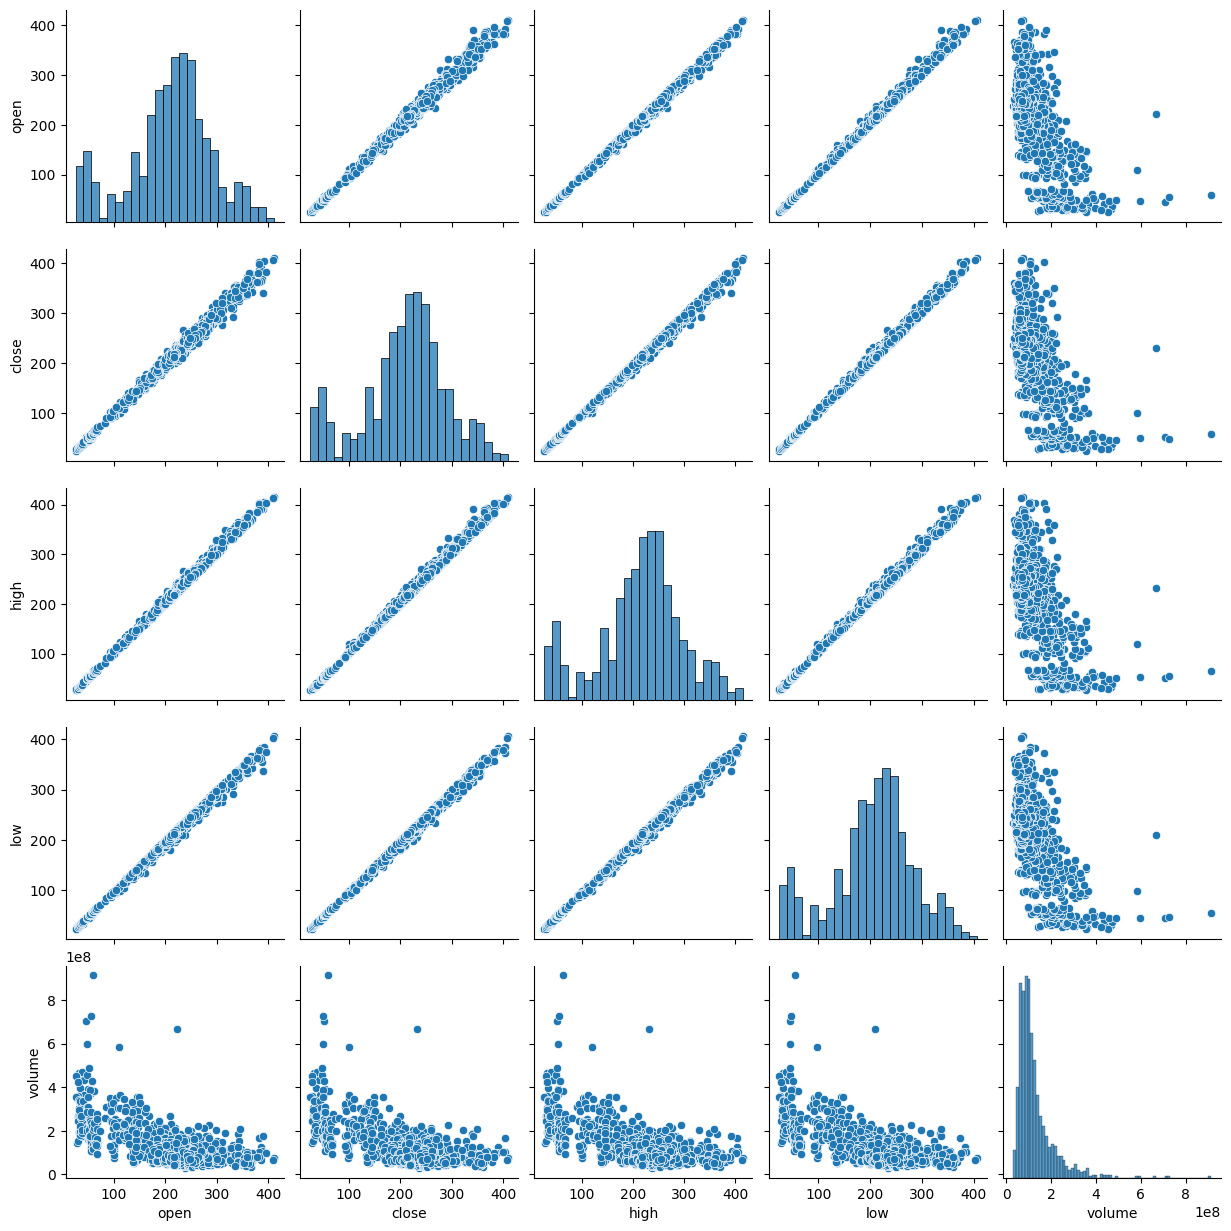

In [161]:
# Create pair plot
sns.pairplot(maindf[['open', 'close', 'high', 'low', 'volume']])
plt.show()


# Prepare Stock Close price

### Make separate dataframe of close price

In [162]:
pricedf = maindf[['date','close','high','low','open','volume']]
print("Shape of close dataframe:", pricedf.shape)

Shape of close dataframe: (1241, 6)


<a name="pclose"></a>

### Plotting Stock Close price chart

In [163]:
# Create the figure
fig = go.Figure()

# Add the close price line trace
fig.add_trace(go.Scatter(
    x=pricedf['date'], 
    y=pricedf['close'], 
    mode='lines', 
    name='Close Stock Price (USD)',
    line=dict(width=2),
    opacity=0.8
))

# Update layout
fig.update_layout(
    title_text='Stock Close Price Chart - Starting From 2020',
    xaxis_title='Date',
    yaxis_title='Close Stock Price (USD)',
    plot_bgcolor='white',
    font_size=15,
    font_color='black'
)

# Remove gridlines
fig.update_xaxes(showgrid=False)
fig.update_yaxes(showgrid=False)

# Show the figure
fig.show()


<a name="year"></a>

# Consider period for prediction

In [164]:
# pricedf = pricedf[pricedf['date'] > '2023-08-16']  #ignored so that the sample size is large
# #IMPORTANT
close_stock = pricedf.copy()
print("Total data for prediction: ",pricedf.shape[0])
pricedf

Total data for prediction:  1241


,date,close,high,low,open,volume
0,2020-01-02 00:00:00+00:00,28.684000,28.713333,28.114000,28.299999,142981500
1,2020-01-03 00:00:00+00:00,29.534000,30.266666,29.128000,29.366667,266677500
2,2020-01-06 00:00:00+00:00,30.102667,30.104000,29.333332,29.364668,151995000
3,2020-01-07 00:00:00+00:00,31.270666,31.441999,30.224001,30.760000,268231500
4,2020-01-08 00:00:00+00:00,32.809334,33.232666,31.215334,31.580000,467164500
...,...,...,...,...,...,...
1236,2024-11-29 00:00:00+00:00,345.160004,345.450012,334.649994,336.079987,37167600
1237,2024-12-02 00:00:00+00:00,357.089996,360.000000,351.149994,352.380005,77986500
1238,2024-12-03 00:00:00+00:00,351.420013,355.690002,348.200012,351.799988,58267200
1239,2024-12-04 00:00:00+00:00,357.929993,358.100006,348.600006,353.000000,50810900


In [165]:
closedf = pricedf[['date', 'close']]
closedf

,date,close
0,2020-01-02 00:00:00+00:00,28.684000
1,2020-01-03 00:00:00+00:00,29.534000
2,2020-01-06 00:00:00+00:00,30.102667
3,2020-01-07 00:00:00+00:00,31.270666
4,2020-01-08 00:00:00+00:00,32.809334
...,...,...
1236,2024-11-29 00:00:00+00:00,345.160004
1237,2024-12-02 00:00:00+00:00,357.089996
1238,2024-12-03 00:00:00+00:00,351.420013
1239,2024-12-04 00:00:00+00:00,357.929993


## Feature Engineering

**Featured Data that are calculated:**
- Moving Average 14-day and 21-day
- Moving Average Convergence and Divergence (MACD)
- Relative Strength Index (RSI)
- Pivot Points and Supports and Resistance
- Average True Range
- Bollinger Bands
- On Balance Volume
- Stochastic Oscillator


In [166]:
# 14-day and 21-day moving averages
pricedf['MA_14'] = pricedf['close'].rolling(window=14).mean()
pricedf['MA_21'] = pricedf['close'].rolling(window=21).mean()
pricedf['MA_50'] = pricedf['close'].rolling(window=50).mean()

# MACD
pricedf['EMA_12'] = pricedf['close'].ewm(span=12, adjust=False).mean()
pricedf['EMA_26'] = pricedf['close'].ewm(span=26, adjust=False).mean()
pricedf['MACD'] = pricedf['EMA_12'] - pricedf['EMA_26']
pricedf['MACD_signal'] = pricedf['MACD'].ewm(span=9, adjust=False).mean()



In [167]:
def calculate_rsi(data, window=50):
    delta = data['close'].diff(1)
    gain = delta.where(delta > 0, 0)
    loss = -delta.where(delta < 0, 0)
    
    avg_gain = gain.rolling(window=window).mean()
    avg_loss = loss.rolling(window=window).mean()
    
    rs = avg_gain / avg_loss
    rsi = 100 - (100 / (1 + rs))
    return rsi

# Example usage:
# Assuming you have a DataFrame `df` with a 'Close' column
pricedf['RSI_50'] = calculate_rsi(pricedf)

In [168]:
# Pivot Points
pricedf['Pivot'] = (pricedf['high'] + pricedf['low'] + pricedf['close']) / 3
pricedf['Pivot_R1'] = 2 * pricedf['Pivot'] - pricedf['low']
pricedf['Pivot_S1'] = 2 * pricedf['Pivot'] - pricedf['high']
pricedf['Pivot_R2'] = pricedf['Pivot'] + (pricedf['high'] - pricedf['low'])
pricedf['Pivot_S2'] = pricedf['Pivot'] - (pricedf['high'] - pricedf['low'])


In [169]:
# ATR (Average True Range)
pricedf['TR'] = pricedf[['high', 'low', 'close']].max(axis=1) - pricedf[['high', 'low', 'close']].min(axis=1)
pricedf['ATR'] = pricedf['TR'].rolling(window=14).mean()

# Bollinger Bands
pricedf['20_MA'] = pricedf['close'].rolling(window=20).mean()
pricedf['BB_upper'] = pricedf['20_MA'] + (pricedf['close'].rolling(window=20).std() * 2)
pricedf['BB_lower'] = pricedf['20_MA'] - (pricedf['close'].rolling(window=20).std() * 2)


In [170]:
# OBV (On-Balance Volume)
pricedf['OBV'] = (np.sign(pricedf['close'].diff()) * pricedf['volume']).fillna(0).cumsum()

In [171]:
# Stochastic Oscillator
pricedf['14-high'] = pricedf['high'].rolling(14).max()
pricedf['14-low'] = pricedf['low'].rolling(14).min()
pricedf['%K'] = (pricedf['close'] - pricedf['14-low']) * 100 / (pricedf['14-high'] - pricedf['14-low'])
pricedf['%D'] = pricedf['%K'].rolling(3).mean()


In [172]:
pd.set_option('display.max_columns', None)
pricedf

,date,close,high,low,open,volume,MA_14,MA_21,MA_50,EMA_12,EMA_26,MACD,MACD_signal,RSI_50,Pivot,Pivot_R1,Pivot_S1,Pivot_R2,Pivot_S2,TR,ATR,20_MA,BB_upper,BB_lower,OBV,14-high,14-low,%K,%D
0,2020-01-02 00:00:00+00:00,28.684000,28.713333,28.114000,28.299999,142981500,NaN,NaN,NaN,28.684000,28.684000,0.000000,0.000000,NaN,28.503778,28.893555,28.294223,29.103111,27.904445,0.599333,NaN,NaN,NaN,NaN,0.000000e+00,NaN,NaN,NaN,NaN
1,2020-01-03 00:00:00+00:00,29.534000,30.266666,29.128000,29.366667,266677500,NaN,NaN,NaN,28.814769,28.746963,0.067806,0.013561,NaN,29.642889,30.157778,29.019112,30.781555,28.504223,1.138666,NaN,NaN,NaN,NaN,2.666775e+08,NaN,NaN,NaN,NaN
2,2020-01-06 00:00:00+00:00,30.102667,30.104000,29.333332,29.364668,151995000,NaN,NaN,NaN,29.012907,28.847386,0.165522,0.043953,NaN,29.846666,30.360001,29.589333,30.617334,29.075998,0.770668,NaN,NaN,NaN,NaN,4.186725e+08,NaN,NaN,NaN,NaN
3,2020-01-07 00:00:00+00:00,31.270666,31.441999,30.224001,30.760000,268231500,NaN,NaN,NaN,29.360255,29.026888,0.333367,0.101836,NaN,30.978889,31.733777,30.515778,32.196887,29.760890,1.217999,NaN,NaN,NaN,NaN,6.869040e+08,NaN,NaN,NaN,NaN
4,2020-01-08 00:00:00+00:00,32.809334,33.232666,31.215334,31.580000,467164500,NaN,NaN,NaN,29.890882,29.307069,0.583813,0.198232,NaN,32.419111,33.622889,31.605556,34.436443,30.401779,2.017332,NaN,NaN,NaN,NaN,1.154068e+09,NaN,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1236,2024-11-29 00:00:00+00:00,345.160004,345.450012,334.649994,336.079987,37167600,336.747857,314.963810,272.643800,332.244449,309.474256,22.770193,23.771269,61.682978,341.753337,348.856679,338.056661,352.553355,330.953318,10.800018,17.581427,318.219500,387.426000,249.012999,1.676449e+10,361.929993,309.220001,68.184421,63.994404
1237,2024-12-02 00:00:00+00:00,357.089996,360.000000,351.149994,352.380005,77986500,337.254286,320.070476,275.020600,336.066841,313.001348,23.065493,23.630114,63.518680,356.079997,361.010000,352.159993,364.930003,347.229991,8.850006,16.596427,323.625000,386.675075,260.574925,1.684248e+10,361.929993,309.220001,90.817687,71.272585
1238,2024-12-03 00:00:00+00:00,351.420013,355.690002,348.200012,351.799988,58267200,338.892144,324.948572,277.049001,338.428867,315.847175,22.581693,23.420430,61.698891,351.770009,355.340007,347.850016,359.260000,344.280019,7.489990,15.522141,329.054001,380.434105,277.673897,1.678421e+10,361.929993,309.220001,80.060746,79.687618
1239,2024-12-04 00:00:00+00:00,357.929993,358.100006,348.600006,353.000000,50810900,340.870002,330.429048,279.122200,341.429041,318.964421,22.464620,23.229268,61.895801,354.876668,361.153330,351.653330,364.376668,345.376668,9.500000,14.622140,334.378500,372.165941,296.591060,1.683502e+10,361.929993,309.220001,92.411306,87.763246


### Remove NA rows

In [173]:
pricedf = pricedf.dropna()
pricedf

,date,close,high,low,open,volume,MA_14,MA_21,MA_50,EMA_12,EMA_26,MACD,MACD_signal,RSI_50,Pivot,Pivot_R1,Pivot_S1,Pivot_R2,Pivot_S2,TR,ATR,20_MA,BB_upper,BB_lower,OBV,14-high,14-low,%K,%D
49,2020-03-13 00:00:00+00:00,36.441334,40.504665,33.466667,39.666668,339604500,45.652762,49.527396,43.886280,43.966474,45.887629,-1.921156,0.169677,53.781311,36.804222,40.141777,33.103779,43.842220,29.766224,7.037998,3.852667,49.323766,64.060697,34.586836,2.931429e+09,57.106667,33.466667,12.583192,8.859697
50,2020-03-16 00:00:00+00:00,29.671333,32.991333,29.478001,31.299999,307342500,43.963048,48.387936,43.906026,41.767221,44.686422,-2.919201,-0.448099,50.451478,30.713556,31.949111,28.435778,34.226888,27.200223,3.513332,3.772190,48.140566,65.146556,31.134576,2.624086e+09,54.220669,29.478001,0.781374,5.957347
51,2020-03-17 00:00:00+00:00,28.680000,31.456667,26.400000,29.334000,359919000,42.303048,47.213873,43.888946,39.753803,43.500761,-3.746959,-1.107871,49.609996,28.845556,31.291112,26.234444,33.902223,23.788888,5.056667,3.956238,46.713233,65.232801,28.193665,2.264168e+09,53.798668,26.400000,8.321575,7.228714
52,2020-03-18 00:00:00+00:00,24.081333,26.990667,23.367332,25.933332,356793000,40.789810,45.635523,43.768520,37.342654,42.062285,-4.719632,-1.830223,47.347804,24.813111,26.258890,22.635555,28.436446,21.189776,3.623335,3.878047,44.859233,64.667989,25.050477,1.907374e+09,53.798668,23.367332,2.346268,3.816405
53,2020-03-19 00:00:00+00:00,28.509333,30.133333,23.897333,24.980000,452932500,39.645286,44.080666,43.713293,35.983681,41.058363,-5.074682,-2.479115,48.817679,27.513333,31.129333,24.893333,33.749333,21.277333,6.236000,3.947285,43.286666,63.041181,23.532152,2.360307e+09,53.798668,23.367332,16.897057,9.188300
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
1236,2024-11-29 00:00:00+00:00,345.160004,345.450012,334.649994,336.079987,37167600,336.747857,314.963810,272.643800,332.244449,309.474256,22.770193,23.771269,61.682978,341.753337,348.856679,338.056661,352.553355,330.953318,10.800018,17.581427,318.219500,387.426000,249.012999,1.676449e+10,361.929993,309.220001,68.184421,63.994404
1237,2024-12-02 00:00:00+00:00,357.089996,360.000000,351.149994,352.380005,77986500,337.254286,320.070476,275.020600,336.066841,313.001348,23.065493,23.630114,63.518680,356.079997,361.010000,352.159993,364.930003,347.229991,8.850006,16.596427,323.625000,386.675075,260.574925,1.684248e+10,361.929993,309.220001,90.817687,71.272585
1238,2024-12-03 00:00:00+00:00,351.420013,355.690002,348.200012,351.799988,58267200,338.892144,324.948572,277.049001,338.428867,315.847175,22.581693,23.420430,61.698891,351.770009,355.340007,347.850016,359.260000,344.280019,7.489990,15.522141,329.054001,380.434105,277.673897,1.678421e+10,361.929993,309.220001,80.060746,79.687618
1239,2024-12-04 00:00:00+00:00,357.929993,358.100006,348.600006,353.000000,50810900,340.870002,330.429048,279.122200,341.429041,318.964421,22.464620,23.229268,61.895801,354.876668,361.153330,351.653330,364.376668,345.376668,9.500000,14.622140,334.378500,372.165941,296.591060,1.683502e+10,361.929993,309.220001,92.411306,87.763246


In [174]:
pricedf.columns

Index(['date', 'close', 'high', 'low', 'open', 'volume', 'MA_14', 'MA_21',
       'MA_50', 'EMA_12', 'EMA_26', 'MACD', 'MACD_signal', 'RSI_50', 'Pivot',
       'Pivot_R1', 'Pivot_S1', 'Pivot_R2', 'Pivot_S2', 'TR', 'ATR', '20_MA',
       'BB_upper', 'BB_lower', 'OBV', '14-high', '14-low', '%K', '%D'],
      dtype='object')

### Visualization of Moving Averages

In [175]:
# Sample dataframe (replace with your data)
df = pricedf

# Melt the DataFrame for easier plotting with Plotly Express
df_melted = df.melt(id_vars='date', value_vars=['close', 'MA_14', 'MA_21', 'MA_50'],
                    var_name='Type', value_name='Price')

# Create Plotly Express line plot
fig = px.line(
    df_melted, 
    x='date', 
    y='Price', 
    color='Type',
    title="Close Price with 14-day, 21-day and 50-day Moving Averages"
)

# Update layout to move the legend to the right and set line styles
fig.update_layout(
    xaxis_title="Date",
    yaxis_title="Price",
    legend=dict(
        orientation="v",
        yanchor="top",
        y=1,
        xanchor="left",
        x=1.02  # Position legend to the right
    )
)

# Display the plot
fig.show()


### Visualizaiton of Moving Average Convergence & Divergence (MACD)

In [176]:

df = pricedf


# Create subplots with shared x-axis
fig = make_subplots(
    rows=2, cols=1,
    shared_xaxes=True,
    vertical_spacing=0.1,
    row_heights=[0.6, 0.4],  # Adjust heights of the subplots
    subplot_titles=('Close Price', 'MACD and Signal Line'),
    row_titles=('Price', 'MACD')
)

# Close price plot (using Plotly Express for aesthetics)
close_fig = px.line(df, x='date', y='close', title="Close Price")
for trace in close_fig['data']:
    fig.add_trace(trace, row=1, col=1)

# MACD histogram bar plot
fig.add_trace(
    go.Bar(x=df['date'], y=df['MACD']-df['MACD_signal'], name='MACD Histogram', marker=dict(
            color=(df['MACD']-df['MACD_signal']).apply(lambda x: '#26A69A' if x >= 0 else '#FF5252'),
            opacity=0.8  # Adjust opacity (0-1)
        ),
        marker_line=dict(  # Add border to bars
            width=1,
            color=(df['MACD']-df['MACD_signal']).apply(lambda x: '#1B5E20' if x >= 0 else '#B71C1C')
        )),
    row=2, col=1
)

# EMA lines (macd signal and smoothing signal)
fig.add_trace(
    go.Scatter(x=df['date'], y=df['MACD'], mode='lines', name='MACD Signal', line=dict(color='blue')),
    row=2, col=1
)



fig.add_trace(
    go.Scatter(x=df['date'], y=df['MACD_signal'], mode='lines', name='Smooth MACD Singal', line=dict(color='orange')),
    row=2, col=1
)


# Update layout for aesthetics and y-axis range
fig.update_layout(
    title="Close Price and MACD Indicator",
    xaxis_title="Date",
    yaxis_title="Price",
    yaxis2_title="MACD Value",
    height=800,
    width=1200,  # Added width parameter
    showlegend=True,
    legend=dict(
        orientation="h",  # Horizontal legend
        yanchor="bottom",
        y=1.02,
        xanchor="right",
        x=1
    ),
    margin=dict(l=50, r=50, t=80, b=50)  # Adjust margins
)

# Update x-axis settings for better date display
fig.update_xaxes(
    rangeslider_visible=False,
    tickangle=-45,
    tickmode='auto',
    nticks=20
)

fig.show()


### Visualization of Relative Index Strength (RSI)

In [177]:

overbought = 70
oversold = 30



# Create subplots: 2 rows, 1 column
fig = make_subplots(
    rows=2, cols=1,
    shared_xaxes=True,
    vertical_spacing=0.1,
    row_heights=[0.6, 0.4],  # Adjust heights of the subplots
    subplot_titles=('Close Price', 'RSI (Relative Strength Index)'),
    row_titles=('Price', 'RSI')
)

# Plot Close Price in the first subplot
fig.add_trace(go.Scatter(x=df.index, y=df['close'], mode='lines', name='Close', line=dict(color='#FF6D00')),
              row=1, col=1)

# Plot RSI in the second subplot
fig.add_trace(go.Scatter(x=df.index, y=df['RSI_50'], mode='lines', name='RSI_50', line=dict(color='#2962FF')),
              row=2, col=1)

# Add overbought and oversold lines to the RSI plot
fig.add_trace(go.Scatter(x=df.index, y=[overbought]*len(df), mode='lines', name='Overbought (70)',
                         line=dict(color='red', dash='dash')),
              row=2, col=1)

fig.add_trace(go.Scatter(x=df.index, y=[oversold]*len(df), mode='lines', name='Oversold (30)',
                         line=dict(color='green', dash='dash')),
              row=2, col=1)

# Update layout
fig.update_layout(
    title="Close Price and RSI Indicator",
    xaxis_title="Date",
    yaxis_title="Price",
    yaxis2_title="RSI Value",
    height=800
)

# Show the plot
fig.show()


### Visualization of Pivot points and Average True Range 

In [178]:
# Create subplots: Close price with Pivot Points, and ATR below
fig = make_subplots(
    rows=2, cols=1,
    shared_xaxes=True,
    vertical_spacing=0.1,
    row_heights=[0.7, 0.3],
    subplot_titles=('Close Price with Pivot Points', 'Average True Range (ATR)')
)

# Plot Close Price
fig.add_trace(go.Scatter(x=df.index, y=df['close'], mode='lines', name='Close Price', line=dict(color='#FF6D00')),
              row=1, col=1)

# Plot Pivot Points in the Close Price plot
fig.add_trace(go.Scatter(x=df.index, y=df['Pivot'], mode='lines', name='Pivot', line=dict(color='blue', dash='dash')),
              row=1, col=1)
fig.add_trace(go.Scatter(x=df.index, y=df['Pivot_R1'], mode='lines', name='Resistance 1', line=dict(color='green', dash='dash')),
              row=1, col=1)
fig.add_trace(go.Scatter(x=df.index, y=df['Pivot_S1'], mode='lines', name='Support 1', line=dict(color='red', dash='dash')),
              row=1, col=1)
fig.add_trace(go.Scatter(x=df.index, y=df['Pivot_R2'], mode='lines', name='Resistance 2', line=dict(color='green', dash='dot')),
              row=1, col=1)
fig.add_trace(go.Scatter(x=df.index, y=df['Pivot_S2'], mode='lines', name='Support 2', line=dict(color='red', dash='dot')),
              row=1, col=1)

# Plot ATR in the second subplot
fig.add_trace(go.Scatter(x=df.index, y=df['ATR'], mode='lines', name='ATR', line=dict(color='purple')),
              row=2, col=1)

# Update layout for aesthetics
fig.update_layout(
    title="Close Price with Pivot Points and ATR",
    xaxis_title="Date",
    yaxis_title="Price",
    yaxis2_title="ATR Value",

    height=800
)

# Show the plot
fig.show()

### Visualization of Bollinger Band 

In [179]:
# Assuming 'pricedf' is your dataframe
fig = px.line(pricedf, x=pricedf['date'], y=['close', '20_MA', 'BB_upper', 'BB_lower'],
              labels={'value': 'Price', 'variable': 'Legend'},
              title="Close Price and Bollinger Bands")
fig.show()                                                           

### Visualization of On Balance Volume and Stochastic Oscillator

In [180]:
import plotly.graph_objects as go
from plotly.subplots import make_subplots

# Create subplots (3 rows, 1 column)
fig = make_subplots(
    rows=3, cols=1,
    shared_xaxes=True,
    vertical_spacing=0.1,
    subplot_titles=('Close Price', 'On-Balance Volume', 'Stochastic Oscillator'),
    row_heights=[0.4, 0.3, 0.3]  # Adjust the height ratio between the subplots
)

# Add Close Price trace to the first subplot
fig.add_trace(go.Scatter(x=pricedf['date'], y=pricedf['close'], mode='lines', name='Close Price'),
              row=1, col=1)

# Add OBV trace to the second subplot
fig.add_trace(go.Scatter(x=pricedf['date'], y=pricedf['OBV'], mode='lines', name='OBV', line=dict(color='orange')),
              row=2, col=1)

# Add %K and %D traces to the third subplot
fig.add_trace(go.Scatter(x=pricedf['date'], y=pricedf['%K'], mode='lines', name='%K', line=dict(color='blue')),
              row=3, col=1)
fig.add_trace(go.Scatter(x=pricedf['date'], y=pricedf['%D'], mode='lines', name='%D', line=dict(color='red')),
              row=3, col=1)

# Update layout
fig.update_layout(
    title="Close Price, OBV, and Stochastic Oscillator",
    xaxis_title="Date",
    yaxis_title="Close Price",
    xaxis2_title="Date",
    yaxis2_title="OBV",
    xaxis3_title="Date",
    yaxis3_title="Stochastic Oscillator",
    height=1000
)

# Show plot
fig.show()


In [181]:
pricedf.columns

Index(['date', 'close', 'high', 'low', 'open', 'volume', 'MA_14', 'MA_21',
       'MA_50', 'EMA_12', 'EMA_26', 'MACD', 'MACD_signal', 'RSI_50', 'Pivot',
       'Pivot_R1', 'Pivot_S1', 'Pivot_R2', 'Pivot_S2', 'TR', 'ATR', '20_MA',
       'BB_upper', 'BB_lower', 'OBV', '14-high', '14-low', '%K', '%D'],
      dtype='object')

### Correlation of feature data

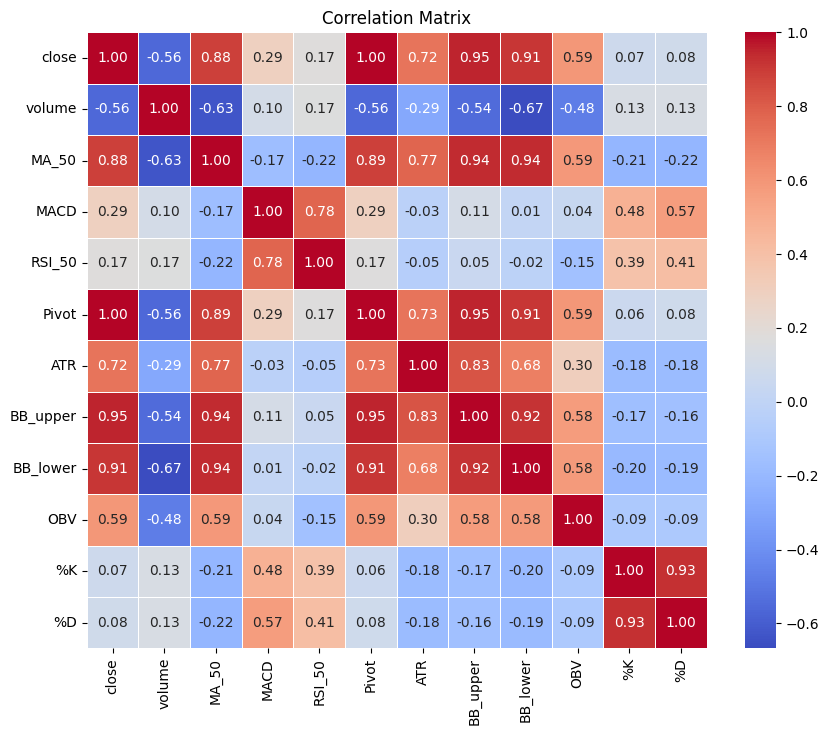

In [182]:
# Calculate correlation matrix
corr_matrix = pricedf[['close', 'volume', 'MA_50', 'MACD', 'RSI_50', 'Pivot', 'ATR', 'BB_upper', 'BB_lower', 'OBV', '%K', '%D']].corr()

# Plot heatmap
plt.figure(figsize=(10, 8))
sns.heatmap(corr_matrix, annot=True, cmap='coolwarm', fmt=".2f", linewidths=0.5)
plt.title('Correlation Matrix')
plt.show()


In this correlation matrix, volume have inverse relationship with all of the price data. Besides, MACD, RSI-50 and Stochastic Oscillator (%K and %D) have less relationship with other data, and hence they play some role in determine the future price data

### Trend Comparison between Close Price and ATR

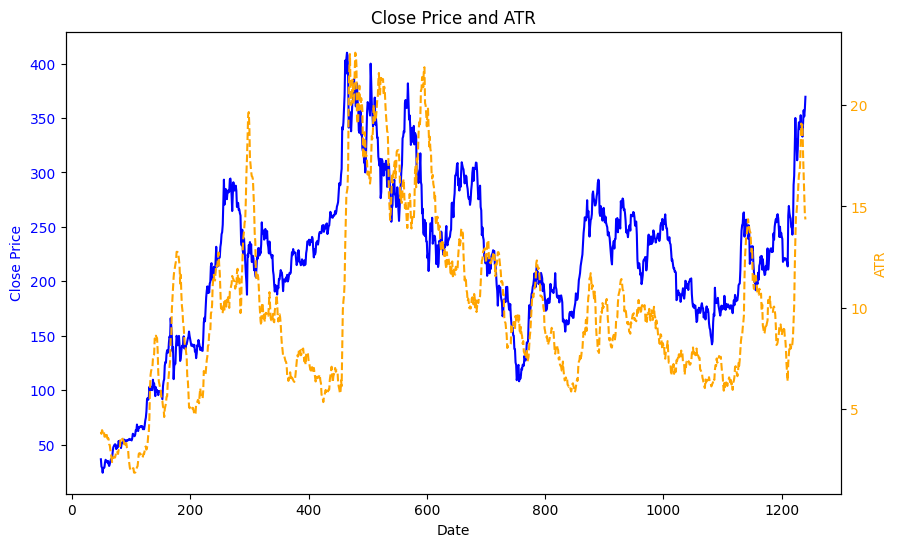

In [183]:
# Plot ATR and close price
fig, ax1 = plt.subplots(figsize=(10, 6))

ax1.plot(pricedf.index, pricedf['close'], color='blue', label='Close Price')
ax1.set_xlabel('Date')
ax1.set_ylabel('Close Price', color='blue')
ax1.tick_params(axis='y', labelcolor='blue')

ax2 = ax1.twinx()
ax2.plot(pricedf.index, pricedf['ATR'], color='orange', label='ATR', linestyle='--')
ax2.set_ylabel('ATR', color='orange')
ax2.tick_params(axis='y', labelcolor='orange')

plt.title('Close Price and ATR')
plt.show()


From the graph above, we can observe that ATR follows the overall trend of the closed price

### Relationship of Featured Data

An overview of the important featured data realtionship

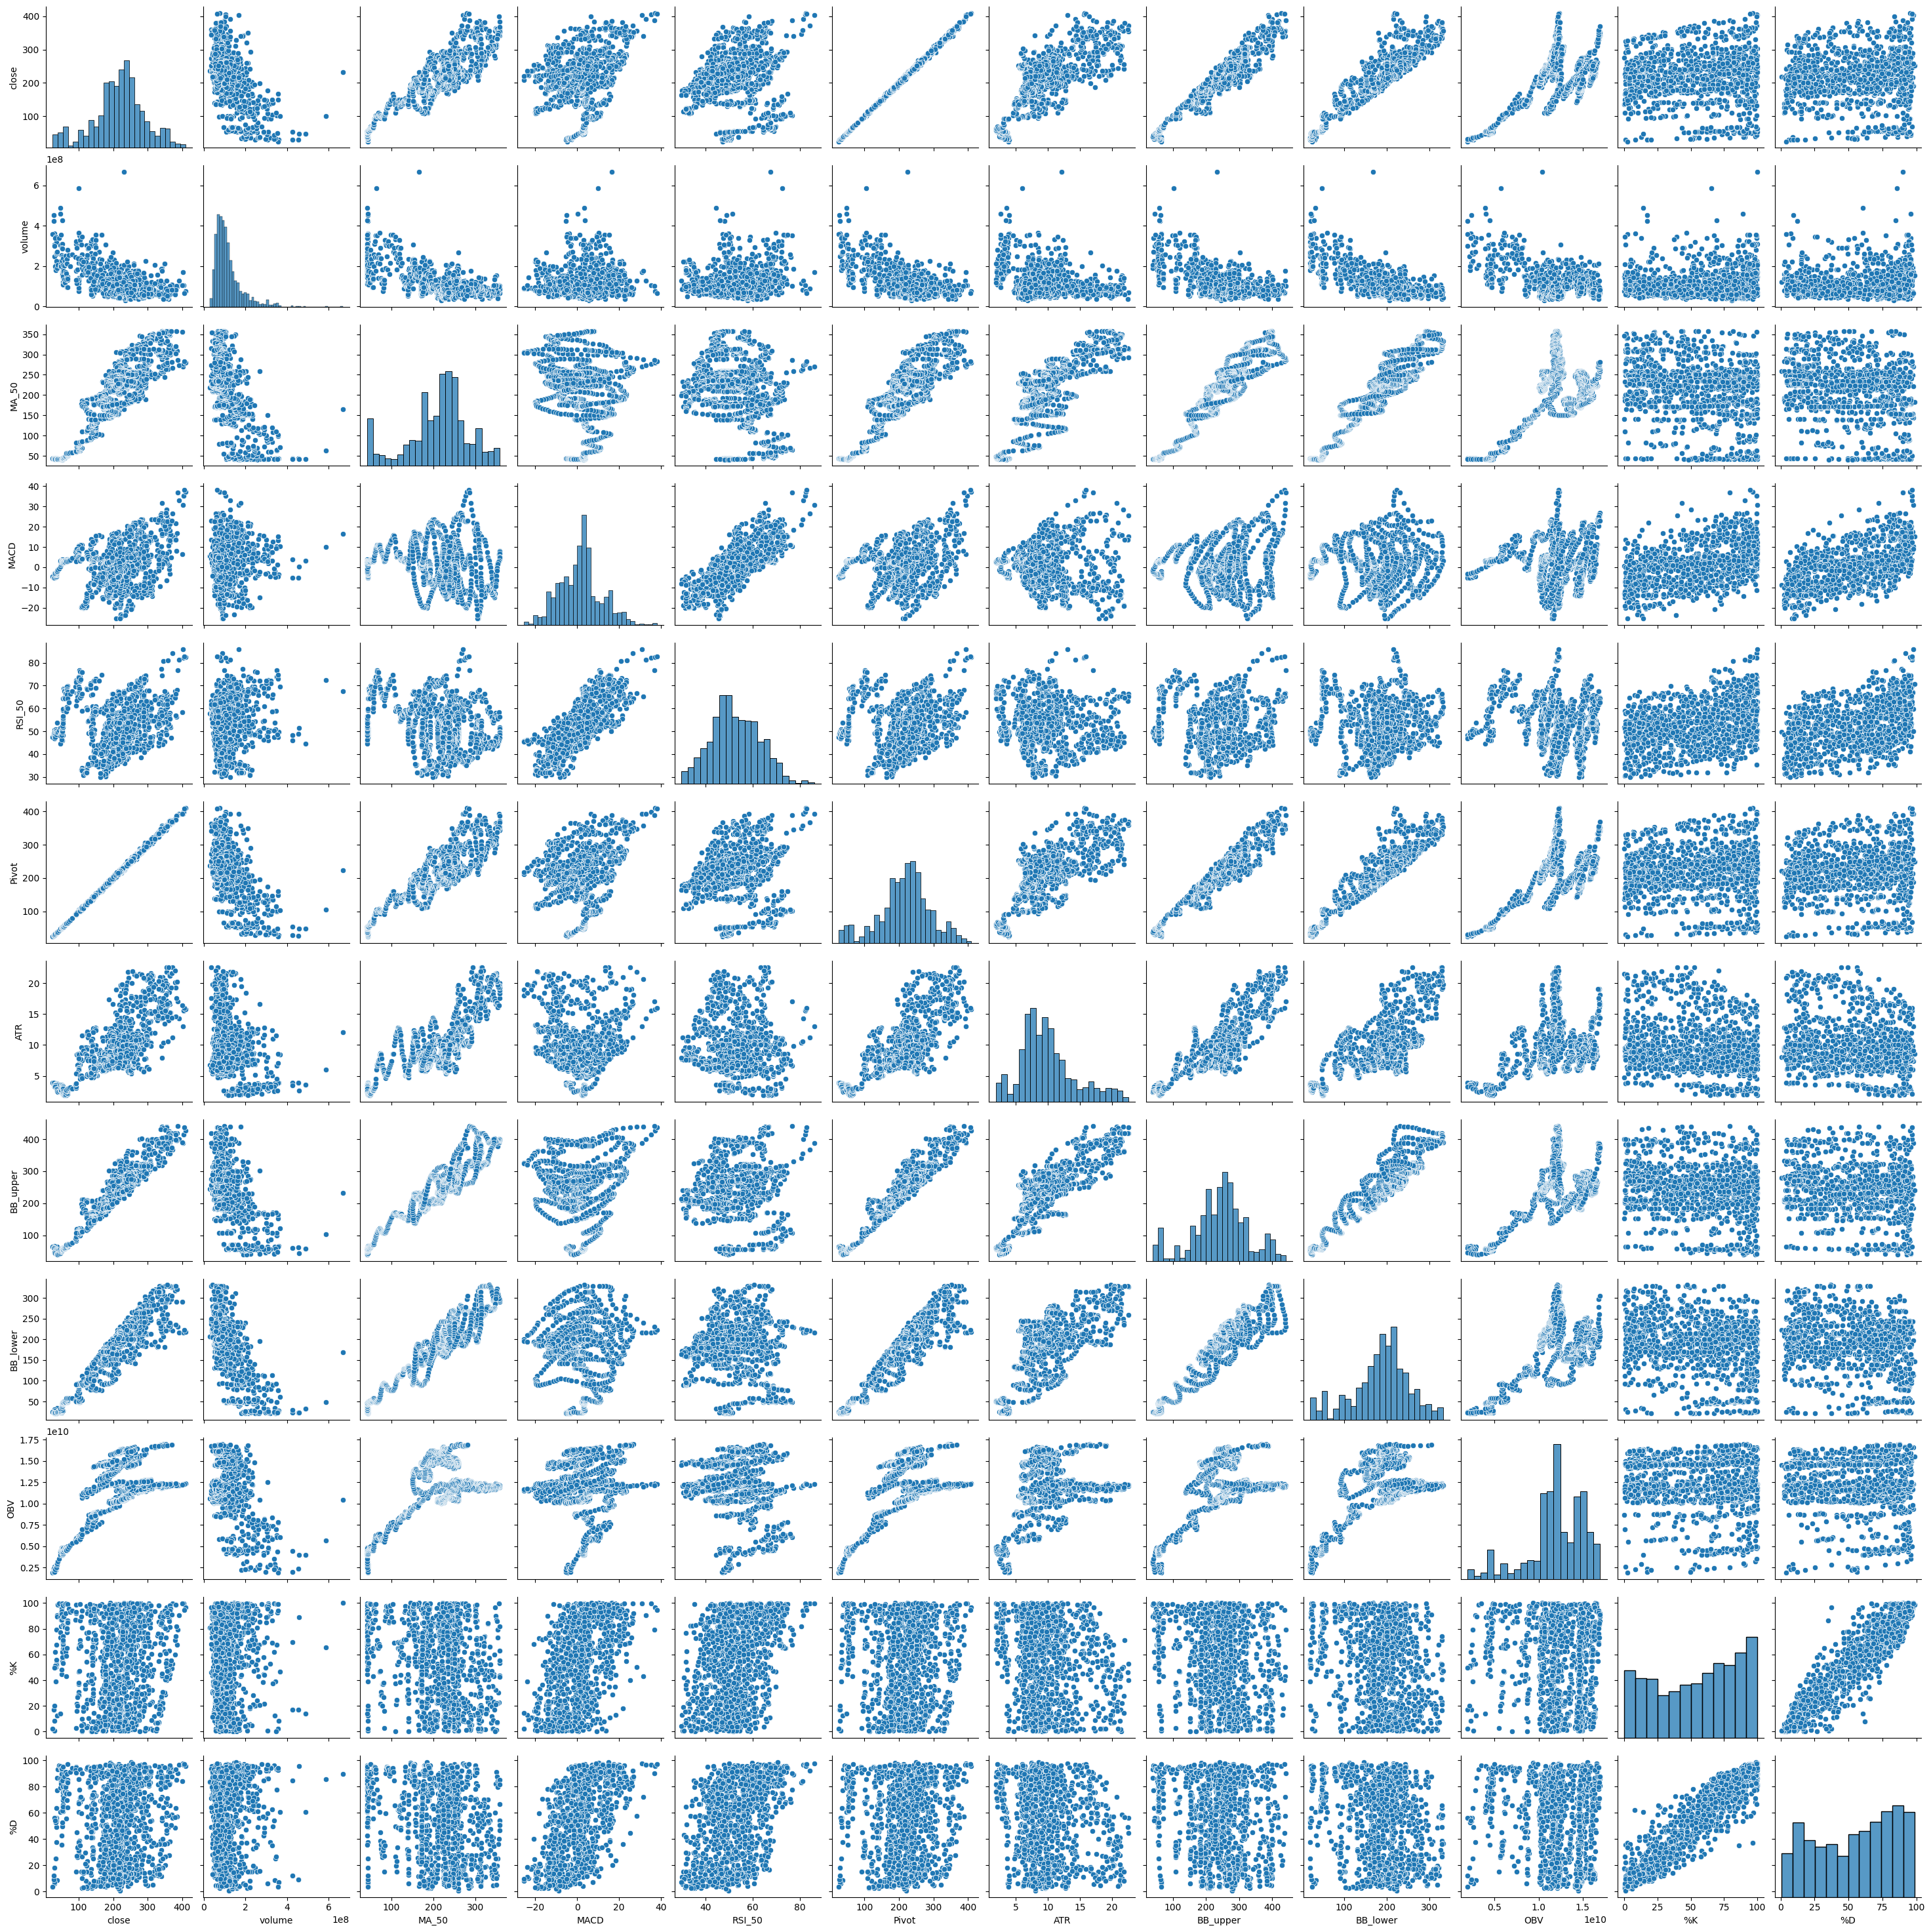

In [184]:
# Create pair plot
sns.pairplot(pricedf[['close', 'volume', 'MA_50', 'MACD', 'RSI_50', 'Pivot', 'ATR', 'BB_upper', 'BB_lower', 'OBV', '%K', '%D']])
plt.show()


<a name="norm"></a>

### Normalizing close price

In [185]:
# Ensure that closedf and pricedf have the same indices by dropping rows with NaNs in pricedf
closedf = closedf.loc[pricedf.dropna().index]
closedf

,date,close
49,2020-03-13 00:00:00+00:00,36.441334
50,2020-03-16 00:00:00+00:00,29.671333
51,2020-03-17 00:00:00+00:00,28.680000
52,2020-03-18 00:00:00+00:00,24.081333
53,2020-03-19 00:00:00+00:00,28.509333
...,...,...
1236,2024-11-29 00:00:00+00:00,345.160004
1237,2024-12-02 00:00:00+00:00,357.089996
1238,2024-12-03 00:00:00+00:00,351.420013
1239,2024-12-04 00:00:00+00:00,357.929993


In [186]:
del closedf['date']
del pricedf['date']
np.save("/Users/keven/Downloads/all/closedf.npy", closedf, allow_pickle=True)
np.save("/Users/keven/Downloads/all/close_stock.npy", close_stock, allow_pickle=True)
scaler1=MinMaxScaler(feature_range=(0,1))
scaler2=MinMaxScaler(feature_range=(0,1))
closedf=scaler1.fit_transform(np.array(closedf))
pricedf=scaler2.fit_transform(np.array(pricedf))
print("Close time-series data shape: ", closedf.shape)
print("Feature Engineered time-series data shape: ", pricedf.shape)

Close time-series data shape:  (1192, 1)
Feature Engineered time-series data shape:  (1192, 28)


<a name="split"></a>

### Prepare Data for train and test

In [187]:
def split_data(dataset, train_ratio=0.65, val_ratio=0.20):
    """
    Splits dataset into training, validation, and test sets.
    
    Parameters:
        dataset (np.array): Dataset to be split.
        train_ratio (float): Proportion of data for training.
        val_ratio (float): Proportion of initial training set for validation.
        
    Returns:
        train_data (np.array): Training data.
        val_data (np.array): Validation data.
        test_data (np.array): Test data.
    """
    # Calculate sizes for each set
    training_size = int(len(dataset) * train_ratio)
    test_size = len(dataset) - training_size
    validation_size = int(training_size * val_ratio)
    
    # Split into train and test sets
    train_data, test_data = dataset[:training_size], dataset[training_size:]
    
    # Further split train_data into actual training and validation sets
    train_data, val_data = train_data[:training_size - validation_size], train_data[training_size - validation_size:]
    
    # Print shapes for verification
    print("train_data: ", train_data.shape)
    print("val_data: ", val_data.shape)
    print("test_data: ", test_data.shape)

    return train_data, val_data, test_data, training_size, validation_size


In [188]:
print("Closed Dataset: ")
close_train_data, close_val_data, close_test_data, close_training_size, close_validation_size = split_data(closedf, train_ratio=0.65, val_ratio=0.20)
print("Feature Dataset: ")
feature_train_data, feature_val_data, feature_test_data, feature_training_size, feature_validation_size = split_data(pricedf, train_ratio=0.65, val_ratio=0.20)

Closed Dataset: 
train_data:  (620, 1)
val_data:  (154, 1)
test_data:  (418, 1)
Feature Dataset: 
train_data:  (620, 28)
val_data:  (154, 28)
test_data:  (418, 28)


### Plot of training, validation and test data

In [189]:
# Extract date and close price from closedf to match each dataset
dates = close_stock['date']  # Original dates in the dataset
prices = close_stock['close']  # Original close prices

# Define the split indices
train_end = close_training_size - close_validation_size

# Split dates and prices
train_dates, train_prices = dates[:train_end], prices[:train_end]
val_dates, val_prices = dates[train_end:close_training_size], prices[train_end:close_training_size]
test_dates, test_prices = dates[close_training_size:], prices[close_training_size:]

# Create a DataFrame for plotting
plot_data = pd.DataFrame({
    'Date': pd.concat([train_dates, val_dates, test_dates]),
    'Price': pd.concat([train_prices, val_prices, test_prices]),
    'Set': (
        ['Training'] * len(train_dates) +
        ['Validation'] * len(val_dates) +
        ['Test'] * len(test_dates)
    )
})

# Plot with Plotly
fig = px.line(
    plot_data,
    x='Date',
    y='Price',
    color='Set',
    labels={'Price': 'Stock Price', 'Date': 'Date'},
    title='Stock Price for Training, Validation, and Test Sets'
)
fig.update_layout(plot_bgcolor='white', font_size=15, font_color='black', legend_title_text='Dataset')
fig.update_xaxes(showgrid=False)
fig.update_yaxes(showgrid=False)
fig.show()


<a name="trans"></a>

### Transform Close price base on Time-series-analysis forecasting requirement

Look below to get bit of understanding about create dataset for forecasting time-series-analysis


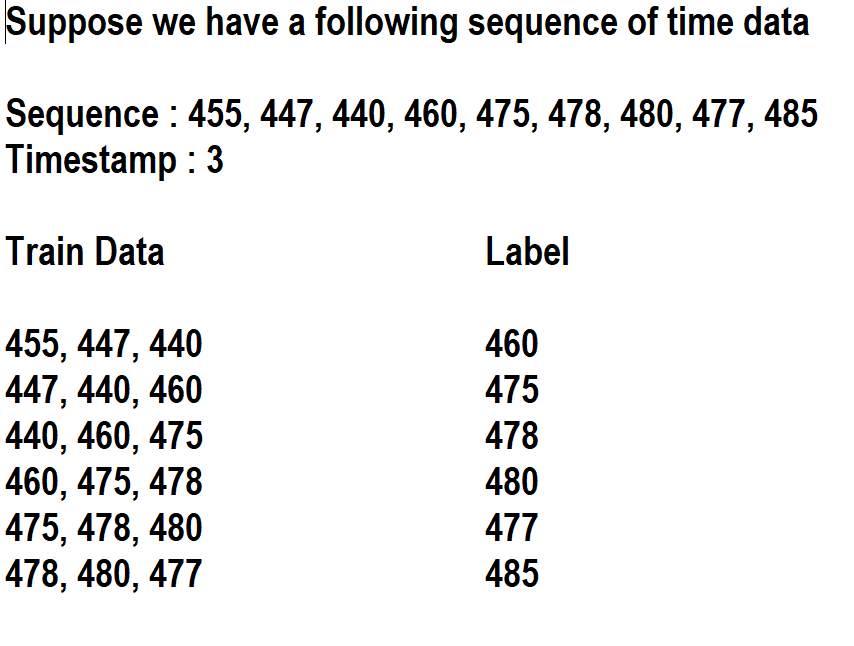


In [190]:
# convert an array of values into a dataset matrix
def create_close_dataset(dataset, time_step=1):
    dataX, dataY = [], []
    for i in range(len(dataset)-time_step-1):
        a = dataset[i:(i+time_step), 0]   ###i=0, 0,1,2,3-----99   100 
        dataX.append(a)
        dataY.append(dataset[i + time_step, 0])
    return np.array(dataX), np.array(dataY)

def create_feature_dataset(dataset, time_step=1, target_col=0):
    dataX, dataY = [], []
    for i in range(len(dataset) - time_step - 1):
        # Take all columns for the input (feature engineering data)
        a = dataset[i:(i + time_step), :]  # use all features for dataX
        dataX.append(a)
        # Use only the close price (or specified target column) for dataY
        dataY.append(dataset[i + time_step, target_col])
    return np.array(dataX), np.array(dataY)


In [191]:
time_step = 15
close_X_train, close_y_train = create_close_dataset(close_train_data, time_step)
close_X_val, close_y_val = create_close_dataset(close_val_data, time_step)
close_X_test, close_y_test = create_close_dataset(close_test_data, time_step)

feature_X_train, feature_y_train = create_feature_dataset(feature_train_data, time_step)
feature_X_val, feature_y_val = create_feature_dataset(feature_val_data, time_step)
feature_X_test, feature_y_test = create_feature_dataset(feature_test_data, time_step)

print("--------------------------------------------------")
print("Close time-series data: ")
print("X_train: ", close_X_train.shape)
print("y_train: ", close_y_train.shape)
print("X_val: ", close_X_val.shape)
print("y_val: ", close_y_val.shape)
print("X_test: ", close_X_test.shape)
print("y_test", close_y_test.shape)
print("--------------------------------------------------")
print("Feature time-series data: ")
print("X_train: ", feature_X_train.shape)
print("y_train: ", feature_y_train.shape)
print("X_val: ", feature_X_val.shape)
print("y_val: ", feature_y_val.shape)
print("X_test: ", feature_X_test.shape)
print("y_test", feature_y_test.shape)
print("--------------------------------------------------")


--------------------------------------------------
Close time-series data: 
X_train:  (604, 15)
y_train:  (604,)
X_val:  (138, 15)
y_val:  (138,)
X_test:  (402, 15)
y_test (402,)
--------------------------------------------------
Feature time-series data: 
X_train:  (604, 15, 28)
y_train:  (604,)
X_val:  (138, 15, 28)
y_val:  (138,)
X_test:  (402, 15, 28)
y_test (402,)
--------------------------------------------------


In [192]:
# reshape input to be [samples, time steps, features] which is required for LSTM
close_X_train = close_X_train.reshape(close_X_train.shape[0],close_X_train.shape[1] , 1)
close_X_val = close_X_val.reshape(close_X_val.shape[0],close_X_val.shape[1] , 1)
close_X_test = close_X_test.reshape(close_X_test.shape[0],close_X_test.shape[1] , 1)

feature_X_train = feature_X_train.reshape(feature_X_train.shape[0],feature_X_train.shape[1] , 28)
feature_X_val = feature_X_val.reshape(feature_X_val.shape[0],feature_X_val.shape[1] , 28)
feature_X_test = feature_X_test.reshape(feature_X_test.shape[0],feature_X_test.shape[1] , 28)

print("--------------------------------------------------")
print("Close time-series data: ")
print("X_train: ", close_X_train.shape)
print("X_val: ", close_X_val.shape)
print("X_test: ", close_X_test.shape)
print("--------------------------------------------------")
print("Feature time-series data: ")
print("X_train: ", feature_X_train.shape)
print("X_val: ", feature_X_val.shape)
print("X_test: ", feature_X_test.shape)
print("--------------------------------------------------")


--------------------------------------------------
Close time-series data: 
X_train:  (604, 15, 1)
X_val:  (138, 15, 1)
X_test:  (402, 15, 1)
--------------------------------------------------
Feature time-series data: 
X_train:  (604, 15, 28)
X_val:  (138, 15, 28)
X_test:  (402, 15, 28)
--------------------------------------------------


# Model Building (LSTM)

**LSTM (Long Short-Term Memory) is a recurrent neural network (RNN) architecture widely used in Deep Learning. It excels at capturing long-term dependencies, making it ideal for sequence prediction tasks.**


In [193]:
from tensorflow.keras.losses import MeanSquaredError

#LSTM model structure
model_close = Sequential()
model_close.add(LSTM(50,return_sequences = True,input_shape = (time_step,1)))
model_close.add(LSTM(50,return_sequences = True))
model_close.add(LSTM(50))
model_close.add(Dropout(0.20))
model_close.add(Dense(1))
model_close.compile(loss = MeanSquaredError(),optimizer = 'adam')

model_feature = Sequential()
model_feature.add(LSTM(50,return_sequences = True,input_shape = (time_step,28)))
model_feature.add(LSTM(50,return_sequences = True))
model_feature.add(LSTM(50))
model_feature.add(Dropout(0.20))
model_feature.add(Dense(1))
model_feature.compile(loss = MeanSquaredError(),optimizer = 'adam')


In [194]:
print(model_close.summary())
print(model_feature.summary())

Model: "sequential_4"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm_12 (LSTM)                  │ (None, 15, 50)         │        10,400 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_13 (LSTM)                  │ (None, 15, 50)         │        20,200 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_14 (LSTM)                  │ (None, 50)             │        20,200 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_4 (Dropout)             │ (None, 50)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 1)              │            51 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 50,851 (198.64 KB)

 Trainable params: 50,851 (198.64 KB)

 Non-trainable params: 0 (0.00 B)

...

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm_15 (LSTM)                  │ (None, 15, 50)         │        15,800 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_16 (LSTM)                  │ (None, 15, 50)         │        20,200 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_17 (LSTM)                  │ (None, 50)             │        20,200 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_5 (Dropout)             │ (None, 50)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 1)              │            51 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 56,251 (219.73 KB)

 Trainable params: 56,251 (219.73 KB)

 Non-trainable params: 0 (0.00 B)

None


### Model Training

In [195]:
from tensorflow.keras.models import load_model
import pickle

if TRAINING == True:
    # Training
    history_close = model_close.fit(close_X_train,close_y_train,validation_data=(close_X_val,close_y_val),epochs=300,batch_size=32,verbose=1)
    history_feature = model_feature.fit(feature_X_train,feature_y_train,validation_data=(feature_X_val,feature_y_val),epochs=300,batch_size=32,verbose=1)

    # Save the model architecture, weights, and optimizer state
    model_close.save("model/model_close.h5")
    model_feature.save("model/model_feature.h5")

    # Save history
    with open("history/model_close_history.pkl", "wb") as file:
        pickle.dump(history_close.history, file)

    with open("history/model_feature_history.pkl", "wb") as file:
        pickle.dump(history_feature.history, file)

if TRAINING == False:
    # Load model
    model_close = load_model("model/model_close.h5")
    model_feature = load_model("model/model_feature.h5")
        
    # Load history
    with open("history/model_close_history.pkl", "rb") as file:
        history_close = pickle.load(file)

    with open("history/model_feature_history.pkl", "rb") as file:
        history_feature = pickle.load(file)

Epoch 1/300
19/19 ━━━━━━━━━━━━━━━━━━━━ 3s 30ms/step - loss: 0.1507 - val_loss: 0.0046
Epoch 2/300
19/19 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - loss: 0.0206 - val_loss: 0.0043
Epoch 3/300
19/19 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - loss: 0.0109 - val_loss: 0.0046
Epoch 4/300
19/19 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - loss: 0.0078 - val_loss: 0.0037
Epoch 5/300
19/19 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - loss: 0.0078 - val_loss: 0.0037
Epoch 6/300
19/19 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - loss: 0.0076 - val_loss: 0.0039
Epoch 7/300
19/19 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - loss: 0.0052 - val_loss: 0.0040
Epoch 8/300
19/19 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - loss: 0.0059 - val_loss: 0.0037
Epoch 9/300
19/19 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - loss: 0.0061 - val_loss: 0.0032
Epoch 10/300
19/19 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - loss: 0.0069 - val_loss: 0.0036
Epoch 11/300
19/19 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - loss: 0.0059 - val_loss: 0.0035
Epoch 12/300
19/19 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step

In [196]:
# Save the feature test data and labels
np.save("/Users/keven/Downloads/all/tf_X_test.npy", feature_X_test, allow_pickle=True)
np.save("/Users/keven/Downloads/all/tf_y_test.npy", feature_y_test, allow_pickle=True)

<a name="loss"></a>

### Plotting loss chart

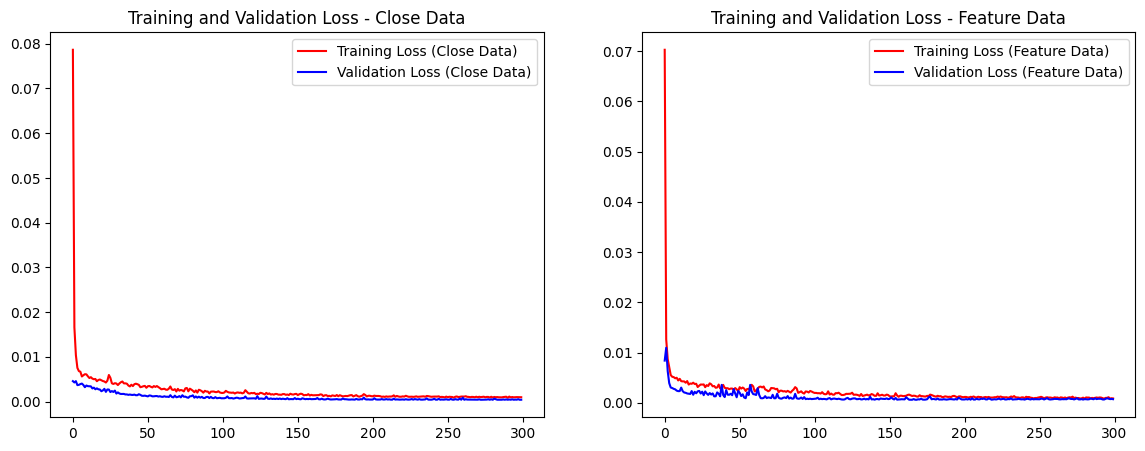

In [197]:
if TRAINING == True:
    # Extract loss values
    close_loss = history_close.history['loss']
    close_val_loss = history_close.history['val_loss']
    feature_loss = history_feature.history['loss']
    feature_val_loss = history_feature.history['val_loss']

if TRAINING == False:
    # Extract loss values directly from the dictionaries
    close_loss = history_close['loss']
    close_val_loss = history_close['val_loss']
    feature_loss = history_feature['loss']
    feature_val_loss = history_feature['val_loss']

epochs_close = range(len(close_loss))
epochs_feature = range(len(feature_loss))

# Create subplots
fig, axs = plt.subplots(1, 2, figsize=(14, 5))

# Plot for close data
axs[0].plot(epochs_close, close_loss, 'r', label='Training Loss (Close Data)')
axs[0].plot(epochs_close, close_val_loss, 'b', label='Validation Loss (Close Data)')
axs[0].set_title('Training and Validation Loss - Close Data')
axs[0].legend(loc="upper right")

# Plot for feature data
axs[1].plot(epochs_feature, feature_loss, 'r', label='Training Loss (Feature Data)')
axs[1].plot(epochs_feature, feature_val_loss, 'b', label='Validation Loss (Feature Data)')
axs[1].set_title('Training and Validation Loss - Feature Data')
axs[1].legend(loc="upper right")

plt.show()


### Prediciton on Train, Validation and Test Data

In [198]:
### Lets Do the prediction and check performance metrics
train_predict_close=model_close.predict(close_X_train)
val_predict_close=model_close.predict(close_X_val)
test_predict_close=model_close.predict(close_X_test)
print(train_predict_close.shape, val_predict_close.shape, test_predict_close.shape)

train_predict_feature=model_feature.predict(feature_X_train)
val_predict_feature=model_feature.predict(feature_X_val)
test_predict_feature=model_feature.predict(feature_X_test)
print(train_predict_feature.shape, val_predict_feature.shape, test_predict_feature.shape)

19/19 ━━━━━━━━━━━━━━━━━━━━ 1s 14ms/step 
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step 
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step 
(604, 1) (138, 1) (402, 1)
19/19 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step
5/5 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step 
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step 
(604, 1) (138, 1) (402, 1)


# Model Evaluation

### Inverse transform prediction & Comparison between predicted values with original values

In [199]:
# Transform back to original form

train_predict_close = scaler1.inverse_transform(train_predict_close)
val_predict_close = scaler1.inverse_transform(val_predict_close)
test_predict_close = scaler1.inverse_transform(test_predict_close)
original_ytrain_close = scaler1.inverse_transform(close_y_train.reshape(-1,1)) 
original_yval_close = scaler1.inverse_transform(close_y_val.reshape(-1,1))
original_ytest_close = scaler1.inverse_transform(close_y_test.reshape(-1,1)) 

#Print the first five predictions for comparision purposes
print("--------------------------------------------------")
print("Train Predicted vs Actual")
print("--------------------------------------------------")
for pred, actual in zip(train_predict_close[:5], original_ytrain_close[:5]):
    print(f"Predicted: {pred[0]:.2f} \t Actual: {actual[0]:.2f}")

print("--------------------------------------------------")
print("Validation Predicted vs Actual")
print("--------------------------------------------------")
for pred, actual in zip(val_predict_close[:5], original_yval_close[:5]):
    print(f"Predicted: {pred[0]:.2f} \t Actual: {actual[0]:.2f}")

print("\n--------------------------------------------------")
print("Test Predicted vs Actual")
print("--------------------------------------------------")
for pred, actual in zip(test_predict_close[:5], original_ytest_close[:5]):
    print(f"Predicted: {pred[0]:.2f} \t Actual: {actual[0]:.2f}")

--------------------------------------------------
Train Predicted vs Actual
--------------------------------------------------
Predicted: 38.83 	 Actual: 32.00
Predicted: 38.34 	 Actual: 34.42
Predicted: 39.20 	 Actual: 36.36
Predicted: 40.87 	 Actual: 36.59
Predicted: 42.24 	 Actual: 38.20
--------------------------------------------------
Validation Predicted vs Actual
--------------------------------------------------
Predicted: 304.48 	 Actual: 308.73
Predicted: 304.13 	 Actual: 300.80
Predicted: 296.57 	 Actual: 288.59
Predicted: 285.19 	 Actual: 275.33
Predicted: 272.94 	 Actual: 276.01

--------------------------------------------------
Test Predicted vs Actual
--------------------------------------------------
Predicted: 163.93 	 Actual: 160.31
Predicted: 162.56 	 Actual: 160.61
Predicted: 161.97 	 Actual: 161.20
Predicted: 162.23 	 Actual: 170.06
Predicted: 167.91 	 Actual: 171.79


In [200]:
# Add dummy columns to match the original shape (e.g., 26 columns)
train_predict_expanded = np.zeros((train_predict_feature.shape[0], 28))
val_predict_expanded = np.zeros((val_predict_feature.shape[0], 28))
test_predict_expanded = np.zeros((test_predict_feature.shape[0], 28))

# Assign predictions to the first column
train_predict_expanded[:, 0] = train_predict_feature[:, 0]
val_predict_expanded[:, 0] = val_predict_feature[:, 0]
test_predict_expanded[:, 0] = test_predict_feature[:, 0]

# Inverse transform and extract only the first column (original target variable)
train_predict_feature = scaler2.inverse_transform(train_predict_expanded)[:, 0].reshape(-1, 1)
val_predict_feature = scaler2.inverse_transform(val_predict_expanded)[:, 0].reshape(-1, 1)
test_predict_feature = scaler2.inverse_transform(test_predict_expanded)[:, 0].reshape(-1, 1)

# Inverse transform original labels similarly
original_ytrain_feature = scaler2.inverse_transform(np.hstack([feature_y_train.reshape(-1, 1), np.zeros((feature_y_train.shape[0], 27))]))[:, 0]
original_yval_feature = scaler2.inverse_transform(np.hstack([feature_y_val.reshape(-1, 1), np.zeros((feature_y_val.shape[0], 27))]))[:, 0]
original_ytest_feature = scaler2.inverse_transform(np.hstack([feature_y_test.reshape(-1, 1), np.zeros((feature_y_test.shape[0], 27))]))[:, 0]

# Print the first five predictions for comparison
print("--------------------------------------------------")
print("Train Predicted vs Actual")
print("--------------------------------------------------")
for pred, actual in zip(train_predict_feature[:5], original_ytrain_feature[:5]):
    print(f"Predicted: {pred[0]:.2f} \t Actual: {actual:.2f}")

print("--------------------------------------------------")
print("Validation Predicted vs Actual")
print("--------------------------------------------------")
for pred, actual in zip(val_predict_feature[:5], original_yval_feature[:5]):
    print(f"Predicted: {pred[0]:.2f} \t Actual: {actual:.2f}")

print("\n--------------------------------------------------")
print("Test Predicted vs Actual")
print("--------------------------------------------------")
for pred, actual in zip(test_predict_feature[:5], original_ytest_feature[:5]):
    print(f"Predicted: {pred[0]:.2f} \t Actual: {actual:.2f}")


--------------------------------------------------
Train Predicted vs Actual
--------------------------------------------------
Predicted: 36.69 	 Actual: 32.00
Predicted: 36.71 	 Actual: 34.42
Predicted: 38.51 	 Actual: 36.36
Predicted: 41.44 	 Actual: 36.59
Predicted: 42.95 	 Actual: 38.20
--------------------------------------------------
Validation Predicted vs Actual
--------------------------------------------------
Predicted: 307.10 	 Actual: 308.73
Predicted: 306.09 	 Actual: 300.80
Predicted: 299.32 	 Actual: 288.59
Predicted: 285.67 	 Actual: 275.33
Predicted: 272.80 	 Actual: 276.01

--------------------------------------------------
Test Predicted vs Actual
--------------------------------------------------
Predicted: 158.22 	 Actual: 160.31
Predicted: 156.62 	 Actual: 160.61
Predicted: 157.19 	 Actual: 161.20
Predicted: 157.92 	 Actual: 170.06
Predicted: 163.91 	 Actual: 171.79


### Evaluation metrices RMSE, MSE and MAE

Root Mean Square Error (RMSE), Mean Square Error (MSE) and Mean absolute Error (MAE) are a standard way to measure the error of a model in predicting quantitative data.

In [201]:
# Metrics for close data
print("--------------------------------------------------")
print("Close Data - Training Performance")
print("--------------------------------------------------")
print("Train data RMSE: ", math.sqrt(mean_squared_error(original_ytrain_close, train_predict_close)))
print("Train data MSE: ", mean_squared_error(original_ytrain_close, train_predict_close))
print("Train data MAE: ", mean_absolute_error(original_ytrain_close, train_predict_close))

print("--------------------------------------------------")
print("Close Data - Test Performance")
print("--------------------------------------------------")
print("Test data RMSE: ", math.sqrt(mean_squared_error(original_ytest_close, test_predict_close)))
print("Test data MSE: ", mean_squared_error(original_ytest_close, test_predict_close))
print("Test data MAE: ", mean_absolute_error(original_ytest_close, test_predict_close))

# Metrics for feature data
print("\n--------------------------------------------------")
print("Feature Data - Training Performance")
print("--------------------------------------------------")
print("Train data RMSE: ", math.sqrt(mean_squared_error(original_ytrain_feature, train_predict_feature)))
print("Train data MSE: ", mean_squared_error(original_ytrain_feature, train_predict_feature))
print("Train data MAE: ", mean_absolute_error(original_ytrain_feature, train_predict_feature))

print("--------------------------------------------------")
print("Feature Data - Test Performance")
print("--------------------------------------------------")
print("Test data RMSE: ", math.sqrt(mean_squared_error(original_ytest_feature, test_predict_feature)))
print("Test data MSE: ", mean_squared_error(original_ytest_feature, test_predict_feature))
print("Test data MAE: ", mean_absolute_error(original_ytest_feature, test_predict_feature))
print("--------------------------------------------------")


--------------------------------------------------
Close Data - Training Performance
--------------------------------------------------
Train data RMSE:  10.165405125247585
Train data MSE:  103.33546136040985
Train data MAE:  7.378379190204948
--------------------------------------------------
Close Data - Test Performance
--------------------------------------------------
Test data RMSE:  8.589087486349543
Test data MSE:  73.77242384816631
Test data MAE:  6.047065279377039

--------------------------------------------------
Feature Data - Training Performance
--------------------------------------------------
Train data RMSE:  9.03551190509184
Train data MSE:  81.64047538705637
Train data MAE:  6.558338265162651
--------------------------------------------------
Feature Data - Test Performance
--------------------------------------------------
Test data RMSE:  11.57791915732534
Test data MSE:  134.0482120135611
Test data MAE:  8.934385955171996
----------------------------------------

<a name="var"></a>

### Explained variance regression score


The explained variance score explains the dispersion of errors of a given dataset, and the formula is written as follows: Here, and Var(y) is the variance of prediction errors and actual values respectively. Scores close to 1.0 are highly desired, indicating better squares of standard deviations of errors.

In [202]:
# Explained variance for close data
print("--------------------------------------------------")
print("Close Data - Training Performance")
print("--------------------------------------------------")
print("Train data explained variance regression score:", explained_variance_score(original_ytrain_close, train_predict_close))
print("Test data explained variance regression score:", explained_variance_score(original_ytest_close, test_predict_close))

# Explained variance for feature data
print("\n--------------------------------------------------")
print("Feature Data - Training Performance")
print("--------------------------------------------------")
print("Train data explained variance regression score:", explained_variance_score(original_ytrain_feature, train_predict_feature))
print("Test data explained variance regression score:", explained_variance_score(original_ytest_feature, test_predict_feature))
print("--------------------------------------------------")


--------------------------------------------------
Close Data - Training Performance
--------------------------------------------------
Train data explained variance regression score: 0.987394042981421
Test data explained variance regression score: 0.9593147473125256

--------------------------------------------------
Feature Data - Training Performance
--------------------------------------------------
Train data explained variance regression score: 0.9898012034487937
Test data explained variance regression score: 0.9539582537070713
--------------------------------------------------


### R2 score for regression

R-squared (R2) is a statistical measure that represents the proportion of the variance for a dependent variable that's explained by an independent variable or variables in a regression model.

1 = Best <br>
0 or < 0 = worse

In [203]:
# R² score for close data
print("--------------------------------------------------")
print("Close Data - R² Scores")
print("--------------------------------------------------")
print("Train data R² score:", r2_score(original_ytrain_close, train_predict_close))
print("Test data R² score:", r2_score(original_ytest_close, test_predict_close))

# R² score for feature data
print("\n--------------------------------------------------")
print("Feature Data - R² Scores")
print("--------------------------------------------------")
print("Train data R² score:", r2_score(original_ytrain_feature, train_predict_feature))
print("Test data R² score:", r2_score(original_ytest_feature, test_predict_feature))
print("--------------------------------------------------")


--------------------------------------------------
Close Data - R² Scores
--------------------------------------------------
Train data R² score: 0.9869126352450871
Test data R² score: 0.9584148968372617

--------------------------------------------------
Feature Data - R² Scores
--------------------------------------------------
Train data R² score: 0.9896602902228465
Test data R² score: 0.9244377718043065
--------------------------------------------------


### Regression Loss Mean Gamma deviance regression loss (MGD) and Mean Poisson deviance regression loss (MPD)

Mean Gamma Deviance Loss (MGD) is used for positive, skewed data that resembles a gamma distribution. It compares true and predicted values, penalizing larger errors more when targets are smaller. Mean Poisson Deviance Loss (MPD) is suited for count data, like event counts, where it compares actual counts to predicted ones, making it sensitive to discrepancies typical of Poisson-distributed data.

In [204]:
# Deviance scores for close data
print("--------------------------------------------------")
print("Close Data - Deviance Scores")
print("--------------------------------------------------")
print("Train data MGD:", mean_gamma_deviance(original_ytrain_close, train_predict_close))
print("Test data MGD:", mean_gamma_deviance(original_ytest_close, test_predict_close))
print("Train data MPD:", mean_poisson_deviance(original_ytrain_close, train_predict_close))
print("Test data MPD:", mean_poisson_deviance(original_ytest_close, test_predict_close))

# Deviance scores for feature data
print("\n--------------------------------------------------")
print("Feature Data - Deviance Scores")
print("--------------------------------------------------")
print("Train data MGD:", mean_gamma_deviance(original_ytrain_feature, train_predict_feature))
print("Test data MGD:", mean_gamma_deviance(original_ytest_feature, test_predict_feature))
print("Train data MPD:", mean_poisson_deviance(original_ytrain_feature, train_predict_feature))
print("Test data MPD:", mean_poisson_deviance(original_ytest_feature, test_predict_feature))
print("--------------------------------------------------")


--------------------------------------------------
Close Data - Deviance Scores
--------------------------------------------------
Train data MGD: 0.00246162916139851
Test data MGD: 0.001372333287927276
Train data MPD: 0.43059216420489305
Test data MPD: 0.3124258884492338

--------------------------------------------------
Feature Data - Deviance Scores
--------------------------------------------------
Train data MGD: 0.0017039174214331103
Test data MGD: 0.002548209695983501
Train data MPD: 0.330196290130161
Test data MPD: 0.5746162276631811
--------------------------------------------------


# Predictions Comparison

## Performance comparision of original stock close price and predicted close price

In [205]:
def plot_predictions(stock_df, stock_prices, train_predict, val_predict, test_predict, time_step, title="Predicted vs Original Prices"):
    # Initialize empty arrays for plotting
    look_back = time_step
    trainPredictPlot = np.empty_like(stock_df)
    trainPredictPlot[:, :] = np.nan
    trainPredictPlot[look_back:len(train_predict) + look_back, :] = train_predict

    # Validation predictions
    valPredictPlot = np.empty_like(stock_df)
    valPredictPlot[:, :] = np.nan
    val_start_index = len(train_predict) + (look_back * 2) + 1
    valPredictPlot[val_start_index:val_start_index + len(val_predict), :] = val_predict

    # Test predictions
    testPredictPlot = np.empty_like(stock_df)
    testPredictPlot[:, :] = np.nan
    test_start_index = val_start_index + len(val_predict) + look_back + 1
    testPredictPlot[test_start_index:test_start_index + len(test_predict), :] = test_predict

    # Ensure stock_prices aligns with trainPredictPlot length
    stock_prices = stock_prices.tail(len(trainPredictPlot)).reset_index(drop=True)
    
    # Verify dimensions match
    assert len(stock_prices) == len(trainPredictPlot), "Mismatch in stock prices and prediction data lengths."

    # Prepare DataFrame for plotting
    plotdf = pd.DataFrame({
        'date': stock_prices['date'],
        'original_price': stock_prices['close'],  # adjust if using another column name
        'train_predicted': trainPredictPlot[:, 0].tolist(),
        'val_predicted': valPredictPlot[:, 0].tolist(),
        'test_predicted': testPredictPlot[:, 0].tolist()
    })

    # Define line names for legend
    names = cycle(['Original price', 'Train predicted price', 'Validation predicted price', 'Test predicted price'])

    # Plot using Plotly
    fig = px.line(plotdf, x=plotdf['date'], y=[
        plotdf['original_price'],
        plotdf['train_predicted'],
        plotdf['val_predicted'],
        plotdf['test_predicted']
    ], labels={'value': 'Stock price', 'date': 'Date'})

    fig.update_layout(
        title_text=title,
        plot_bgcolor='white', font_size=15, font_color='black', legend_title_text='Price'
    )
    fig.for_each_trace(lambda t: t.update(name=next(names)))

    fig.update_xaxes(showgrid=False)
    fig.update_yaxes(showgrid=False)
    fig.show()


In [206]:
plot_predictions(closedf, close_stock, train_predict_close, val_predict_close, test_predict_close, time_step, title="Close Price Predictions")

The close data model is well performed on train data but slightly poor on test data since it may be only rely on close price only.

In [207]:
plot_predictions(pricedf, close_stock, train_predict_feature, val_predict_feature, test_predict_feature, time_step, title="Feature Data Price Predictions")


The feature data model does not perform as well as close data model but it perform better on unseen data. However, the model will assume the range of price and create a bias that price will not drop or rise over a price range. It can be seen in the validation data period

## Performance comparison between Close data Model and Feature data Model in Test Period

In [208]:
def plot_test_period(stock_df, stock_prices, closedf_test_predict, pricedf_test_predict, time_step, title="Test Period Predictions vs Original Price"):
    # Initialize empty arrays for the test period
    look_back = time_step
    test_start_index = len(stock_df) - len(closedf_test_predict)

    # Original stock prices for the test period
    test_stock_prices = stock_prices.tail(len(closedf_test_predict)).reset_index(drop=True)

    # Prepare DataFrame for plotting
    plotdf = pd.DataFrame({
        'date': test_stock_prices['date'],
        'original_price': test_stock_prices['close'],  # adjust if using another column name
        'closedf_test_predicted': closedf_test_predict.flatten(),
        'pricedf_test_predicted': pricedf_test_predict.flatten()
    })

    # Define line names for legend
    names = cycle(['Original price', 'Closedf test predicted price', 'Pricedf test predicted price'])

    # Plot using Plotly
    fig = px.line(plotdf, x=plotdf['date'], y=[
        plotdf['original_price'],
        plotdf['closedf_test_predicted'],
        plotdf['pricedf_test_predicted']
    ], labels={'value': 'Stock price', 'date': 'Date'})

    fig.update_layout(
        title_text=title,
        plot_bgcolor='white', font_size=15, font_color='black', legend_title_text='Price'
    )
    fig.for_each_trace(lambda t: t.update(name=next(names)))

    fig.update_xaxes(showgrid=False)
    fig.update_yaxes(showgrid=False)
    fig.show()


In [209]:

# Call the function with test data predictions for closedf, pricedf, and original stock prices
plot_test_period(closedf, close_stock, test_predict_close, test_predict_feature, time_step, title="Test Period Close Price Predictions")


## Visualization of Outlier Predictions

In [210]:
def plot_test_period(stock_df, stock_prices, closedf_test_predict, pricedf_test_predict, time_step, threshold=1, title="Test Period Predictions vs Original Price"):
    # Ensure date column is in datetime format
    test_stock_prices = stock_prices.tail(len(closedf_test_predict)).reset_index(drop=True)
    test_stock_prices['date'] = pd.to_datetime(test_stock_prices['date'])
    
    # Calculate errors
    closedf_errors = np.abs(test_stock_prices['close'] - closedf_test_predict.flatten())
    pricedf_errors = np.abs(test_stock_prices['close'] - pricedf_test_predict.flatten())

    # Create a DataFrame for plotting
    plotdf = pd.DataFrame({
        'date': test_stock_prices['date'],
        'original_price': test_stock_prices['close'],
        'closedf_test_predicted': closedf_test_predict.flatten(),
        'pricedf_test_predicted': pricedf_test_predict.flatten(),
        'closedf_error': closedf_errors,
        'pricedf_error': pricedf_errors
    })

    # Plot predictions and original prices
    fig = px.line(
        plotdf, x='date', y=['original_price', 'closedf_test_predicted', 'pricedf_test_predicted'],
        labels={'value': 'Stock price', 'date': 'Date'}
    )

    # Add shaded regions for errors exceeding threshold
    for i, row in plotdf.iterrows():
        if row['closedf_error'] > threshold and row['pricedf_error'] > threshold:
            fig.add_shape(
                type="rect",
                x0=row['date'],
                x1=row['date'] + pd.Timedelta(days=1),  # Extend x1 by 1 day
                y0=min(row['original_price'], row['closedf_test_predicted'], row['pricedf_test_predicted']) - threshold,
                y1=max(row['original_price'], row['closedf_test_predicted'], row['pricedf_test_predicted']) + threshold,
                fillcolor="red",
                opacity=0.5,
                line_width=0,
            )
        elif row['closedf_error'] <= threshold or row['pricedf_error'] <= threshold:
            fig.add_shape(
                type="rect",
                x0=row['date'],
                x1=row['date'] + pd.Timedelta(days=1),  # Extend x1 by 1 day
                y0=min(row['original_price'], row['closedf_test_predicted'], row['pricedf_test_predicted']) - threshold,
                y1=max(row['original_price'], row['closedf_test_predicted'], row['pricedf_test_predicted']) + threshold,
                fillcolor="green",
                opacity=0.3,
                line_width=0,
            )

    # Update legend and layout
    line_names = cycle(['Original price', 'Closedf test predicted price', 'Pricedf test predicted price'])
    fig.for_each_trace(lambda t: t.update(name=next(line_names)))

    fig.update_layout(
        title_text=title,
        plot_bgcolor='white', font_size=15, font_color='black', legend_title_text='Price'
    )
    fig.update_xaxes(showgrid=False)
    fig.update_yaxes(showgrid=False)
    fig.show()

# Call function with a threshold value
plot_test_period(closedf, close_stock, test_predict_close, test_predict_feature, time_step, threshold=20, title="Test Period Close Price Predictions with Error Highlights")


Zoom in to have a better picture. The red colour highlighted area are the are where both model predictions are far off from the original price by 20 price points. It can conclude that when a sudden spike or dump in price is hardly to be captured, since it can be manipulated by institutional trader.

# Conclusion and Insights


**In the above picture, the pricedf dataset model have a better performance over the closedf dataset model since it has less lagging factor which it is more reactive to price changes. However, it is not encourage to use these model to perform investing before backtesting because price data always consider as lagging data in the financial market. For further improvement, we can implement sentiment analsyis in model prediction to observe news and event in the financial market through social media. Futhermore, we can broaden our dataset to include fundamental data of a companies such as equity flow, cash debt and revenue, these data are the performance measure of how well a company develop and increase it stock values, since these are events that cause the stock price moves**